In [50]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:
import numpy as np
from pygraphon.graphons import Graphon
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist
from pygraphon.estimators import HistogramEstimator

from utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
import matplotlib.pyplot as plt
from pygraphon.plots.plot_matrices import spy


In [52]:
n = 200
k = 2
theta_intra_min, theta_intra_max = 0.5, 0.7
theta_inter_min, theta_inter_max = 0.1, 0.4
theta = AssociativeFullyRandom(
                    K=k,
                    min_inside_classes=theta_intra_min,
                    max_inside_classes=theta_intra_max,
                    min_outside_classes=theta_inter_min,
                    max_outside_classes=theta_inter_max,
                )
print(theta.Theta)
graphon = StepGraphon(theta.Theta, bandwidthHist=1 / k)
adjacency_matrix = graphon.draw(n=n, exchangeable=False)

[[0.60051552 0.18604392]
 [0.18604392 0.58061995]]


In [53]:
est = SmoothNetHist()
first_hist_olhede = est._first_approximate_graphon_from_adjacency(adjacencyMatrix= adjacency_matrix)

KeyboardInterrupt: 

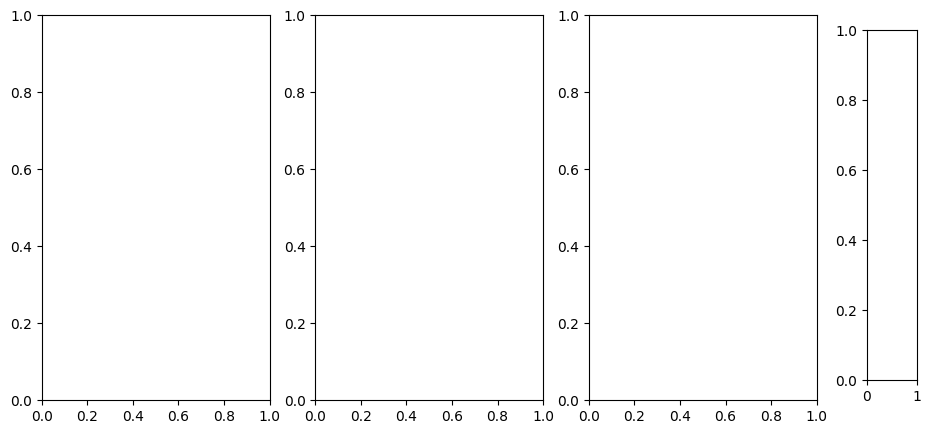

In [54]:
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(first_hist_olhede[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.show()

In [ ]:
my_est = SmoothNetHist()
my_est.fit(adjacency_matrix)

In [ ]:
print("Ratio of parameters:", my_est.get_ratio_par())
print("Number of unique parameters in SmoothNetHist:", len(np.unique(my_est.graphon.get_graphon())))
print("Number of unique parameters in Olhede:", len(np.unique(first_hist_olhede[0].get_graphon())))


Ratio of parameters: 0.10476190476190476
Number of unique parameters in SmoothNetHist: 11
Number of unique parameters in Olhede: 104


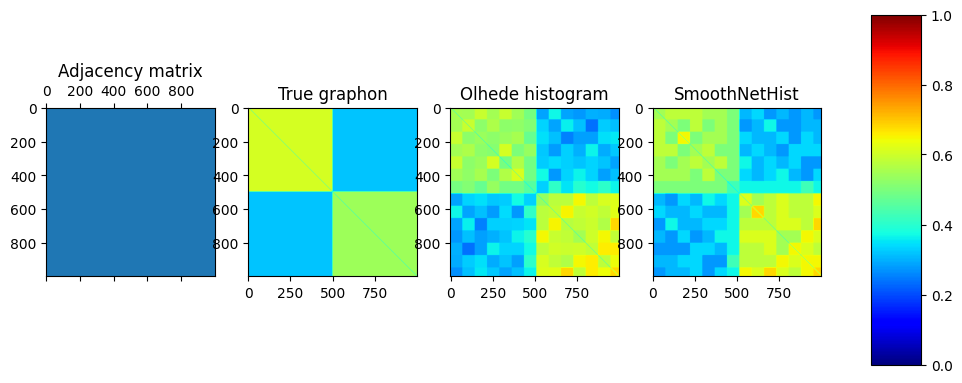

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im1 = ax[1].imshow(graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im2 = ax[2].imshow(first_hist_olhede[0].get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
im3 = ax[3].imshow(my_est.graphon.get_edge_probabilities(n,False,True), cmap='jet', vmin=0, vmax=1)
_ = spy(adjacency_matrix, ax=ax[0])
ax[0].set_title("Adjacency matrix")
ax[1].set_title("True graphon")
ax[2].set_title("Olhede histogram")
ax[3].set_title("SmoothNetHist")
plt.colorbar(im1, cax=cbar_ax)
plt.colorbar(im2, cax=cbar_ax)
plt.colorbar(im3, cax=cbar_ax)
plt.show()